In [1]:
# BLOCK 1: Install and import the required libraries

!pip -q install scikit-learn openpyxl xlrd joblib

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
OUTPUT_DIR = "/content/unit5_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported successfully.")
print("scikit-learn version:", __import__("sklearn").__version__)


Libraries imported successfully.
scikit-learn version: 1.6.1


In [2]:
# BLOCK 2: Upload and read the dataset

uploaded = files.upload()
if not uploaded:
    raise ValueError("No file was uploaded. Please upload the rice dataset in CSV, .xls, or .xlsx format.")

# Support CSV and Excel files
supported_files = [name for name in uploaded if name.lower().endswith((".xls", ".xlsx", ".csv"))]
if not supported_files:
    raise ValueError("Please upload a supported file format (.csv, .xls, or .xlsx).")

file_name = supported_files[0]
if file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name)
else:
    df = pd.read_excel(file_name, engine="openpyxl")

# Remove accidental leading/trailing spaces from column headings.
df.columns = df.columns.astype(str).str.strip()

print("Loaded file:", file_name)
print("Dataset shape:", df.shape)
print("Columns:")
print(df.columns.tolist())
display(df.head())

Saving time series dataset.csv to time series dataset.csv
Loaded file: time series dataset.csv
Dataset shape: (12803, 107)
Columns:
['Dist Code', 'Year', 'State Code', 'State Name', 'Dist Name', 'RICE AREA (1000 ha)', 'RICE PRODUCTION (1000 tons)', 'RICE YIELD (Kg per ha)', 'PEARL MILLET AREA (1000 ha)', 'PEARL MILLET PRODUCTION (1000 tons)', 'PEARL MILLET YIELD (Kg per ha)', 'CHICKPEA AREA (1000 ha)', 'CHICKPEA PRODUCTION (1000 tons)', 'CHICKPEA YIELD (Kg per ha)', 'GROUNDNUT AREA (1000 ha)', 'GROUNDNUT PRODUCTION (1000 tons)', 'GROUNDNUT YIELD (Kg per ha)', 'SUGARCANE AREA (1000 ha)', 'SUGARCANE PRODUCTION (1000 tons)', 'SUGARCANE YIELD (Kg per ha)', 'GROSS CROPPED AREA (1000 ha)', 'NITROGEN CONSUMPTION (tons)', 'PHOSPHATE CONSUMPTION (tons)', 'POTASH CONSUMPTION (tons)', 'TOTAL FERTILISER CONSUMPTION (tons)', 'TOTAL AGRICULTURAL LABOUR POPULATION (1000 Number)', 'GROSS IRRIGATED AREA (1000 ha)', 'JANUARY MAXIMUM TEMPERATURE (Centigrate)', 'FEBRUARY MAXIMUM TEMPERATURE (Centigrate)',

,Dist Code,Year,State Code,State Name,Dist Name,RICE AREA (1000 ha),RICE PRODUCTION (1000 tons),RICE YIELD (Kg per ha),PEARL MILLET AREA (1000 ha),PEARL MILLET PRODUCTION (1000 tons),...,JULY WINDSPEED (Meter per second),AUG WINDSPEED (Meter per second),SEPT WINDSPEED (Meter per second),OCT WINDSPEED (Meter per second),NOV WINDSPEED (Meter per second),DEC WINDSPEED (Meter per second),Winter JAN-FEB WINDSPEED (Meter per second),Summer MAR-MAY WINDSPEED (Meter per second),Rainy JUN-SEP WINDSPEED (Meter per second),Autumn OCT-DEC WINDSPEED (Meter per second)
0,1,1990,14,Chhattisgarh,Durg,397.899994,481.399994,1210.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1991,14,Chhattisgarh,Durg,393.200012,508.600006,1293.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,1992,14,Chhattisgarh,Durg,398.399994,514.500000,1291.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,1993,14,Chhattisgarh,Durg,410.200012,569.099976,1387.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,1994,14,Chhattisgarh,Durg,430.100006,601.700012,1399.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# BLOCK 3: Define the target and predictor features

target = "RICE YIELD (Kg per ha)"

numeric_features = [
    "Year",
    "NITROGEN CONSUMPTION (tons)",
    "PHOSPHATE CONSUMPTION (tons)",
    "POTASH CONSUMPTION (tons)",
    "TOTAL FERTILISER CONSUMPTION (tons)",
    "TOTAL AGRICULTURAL LABOUR POPULATION (1000 Number)",
    "GROSS IRRIGATED AREA (1000 ha)",
    "Rainy JUN-SEP MAXIMUM TEMPERATURE (Centigrate)",
    "Rainy JUN-SEP MINIMUM TEMPERATURE (Centigrate)",
    "Rainy JUN-SEP PERCIPITATION (Millimeters)",
    "Rainy JUN-SEP ACTUAL EVAPOTRANSPIRATION (Millimeters)",
    "Rainy JUN-SEP WINDSPEED (Meter per second)"
]

categorical_features = ["State Name", "Dist Name"]
required_columns = numeric_features + categorical_features + [target]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(
        "The uploaded dataset is missing these required columns:\n"
        + "\n".join(missing_columns)
        + "\nPlease check that you uploaded the correct Unit 5 dataset."
    )

# Keep only columns used in this analysis.
df = df[required_columns].copy()

# Convert numeric columns explicitly. This also handles numbers stored as text.
for col in numeric_features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without a known target or year; those rows cannot be used
# for supervised training or the chronological split.
df = df.dropna(subset=[target, "Year"]).copy()
df["Year"] = df["Year"].astype(int)

# Clean categorical fields while preserving missing values for imputation.
for col in categorical_features:
    df[col] = df[col].astype("string")
    df[col] = df[col].replace({"<NA>": np.nan, "nan": np.nan, "None": np.nan})

# Sort by year for transparent chronological handling.
df = df.sort_values("Year").reset_index(drop=True)

print("Rows available for modelling:", len(df))
print("Year range:", df["Year"].min(), "to", df["Year"].max())
print("Missing target values after cleaning:", df[target].isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.head())


Rows available for modelling: 12751
Year range: 1990 to 2015
Missing target values after cleaning: 0
Duplicate rows: 0


,Year,NITROGEN CONSUMPTION (tons),PHOSPHATE CONSUMPTION (tons),POTASH CONSUMPTION (tons),TOTAL FERTILISER CONSUMPTION (tons),TOTAL AGRICULTURAL LABOUR POPULATION (1000 Number),GROSS IRRIGATED AREA (1000 ha),Rainy JUN-SEP MAXIMUM TEMPERATURE (Centigrate),Rainy JUN-SEP MINIMUM TEMPERATURE (Centigrate),Rainy JUN-SEP PERCIPITATION (Millimeters),Rainy JUN-SEP ACTUAL EVAPOTRANSPIRATION (Millimeters),Rainy JUN-SEP WINDSPEED (Meter per second),State Name,Dist Name,RICE YIELD (Kg per ha)
0,1990,6943.0,3260.0,4386.0,14589.0,NaN,99.889999,32.314999,22.037500,61.062500,60.422501,3.00975,Tamil Nadu,Dharmapuri,3213.0
1,1990,1934.0,1503.0,32.0,3469.0,NaN,27.600000,31.790001,24.817499,357.582489,126.872498,1.53725,Madhya Pradesh,Sidhi,587.0
2,1990,8026.0,3807.0,4906.0,16739.0,NaN,89.239998,31.735001,22.262501,45.537498,44.750000,3.16275,Tamil Nadu,Dindigul Anna,3670.0
3,1990,9994.0,3753.0,5038.0,18785.0,NaN,78.870003,35.000000,25.605000,60.570000,61.540001,3.25200,Tamil Nadu,Pudukkottai,2521.0
4,1990,10765.0,8007.0,141.0,18913.0,NaN,52.400002,31.842501,24.860001,365.209992,129.767502,1.59725,Madhya Pradesh,Satna,588.0


In [4]:
# BLOCK 4: Split the data chronologically

# Train on earlier years and evaluate on later years.
train_df = df[df["Year"].between(1990, 2011)].copy()
test_df = df[df["Year"].between(2012, 2015)].copy()

if train_df.empty or test_df.empty:
    raise ValueError(
        "The selected chronological split is empty. "
        "Check whether the dataset contains records from 1990–2015."
    )

X_train = train_df[numeric_features + categorical_features].copy()
y_train = train_df[target].copy()
X_test = test_df[numeric_features + categorical_features].copy()
y_test = test_df[target].copy()

print("Training records:", len(X_train))
print("Training years:", train_df["Year"].min(), "to", train_df["Year"].max())
print("Testing records:", len(X_test))
print("Testing years:", test_df["Year"].min(), "to", test_df["Year"].max())
print("Training target mean:", round(y_train.mean(), 2), "Kg/ha")


Training records: 10541
Training years: 1990 to 2011
Testing records: 2210
Testing years: 2012 to 2015
Training target mean: 1735.81 Kg/ha


In [5]:
# BLOCK 5: Preprocess features and train the Random Forest model

# Imputation and encoding are fitted only on the training data because
# they are inside the scikit-learn Pipeline.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numbers", numeric_pipeline, numeric_features),
    ("categories", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("random_forest", RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        min_samples_leaf=1
    ))
])

model.fit(X_train, y_train)
print("Random Forest model training completed.")


Random Forest model training completed.


In [6]:
# BLOCK 6: Predict and evaluate the Random Forest model

predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = float(np.sqrt(mean_squared_error(y_test, predictions)))
r2 = r2_score(y_test, predictions)

# Mean baseline: predicts the average yield observed in the training set.
baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(X_train), 1)), y_train)
baseline_predictions = baseline.predict(np.zeros((len(X_test), 1)))
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = float(np.sqrt(mean_squared_error(y_test, baseline_predictions)))
baseline_r2 = r2_score(y_test, baseline_predictions)

metrics = {
    "MAE_Kg_per_ha": float(mae),
    "RMSE_Kg_per_ha": float(rmse),
    "R2": float(r2),
    "Baseline_MAE_Kg_per_ha": float(baseline_mae),
    "Baseline_RMSE_Kg_per_ha": float(baseline_rmse),
    "Baseline_R2": float(baseline_r2)
}

print("RANDOM FOREST REGRESSION RESULTS")
print("--------------------------------")
print(f"MAE  : {mae:.2f} Kg/ha")
print(f"RMSE : {rmse:.2f} Kg/ha")
print(f"R²   : {r2:.4f}")
print("\nMEAN BASELINE RESULTS")
print("---------------------")
print(f"MAE  : {baseline_mae:.2f} Kg/ha")
print(f"RMSE : {baseline_rmse:.2f} Kg/ha")
print(f"R²   : {baseline_r2:.4f}")

results = test_df[["Year", "State Name", "Dist Name"]].copy()
results["Actual Rice Yield (Kg per ha)"] = y_test.to_numpy()
results["Predicted Rice Yield (Kg per ha)"] = predictions
results["Absolute Error (Kg per ha)"] = np.abs(y_test.to_numpy() - predictions)
display(results.head(10))


RANDOM FOREST REGRESSION RESULTS
--------------------------------
MAE  : 480.41 Kg/ha
RMSE : 645.10 Kg/ha
R²   : 0.6867

MEAN BASELINE RESULTS
---------------------
MAE  : 967.39 Kg/ha
RMSE : 1226.80 Kg/ha
R²   : -0.1332


,Year,State Name,Dist Name,Actual Rice Yield (Kg per ha),Predicted Rice Yield (Kg per ha),Absolute Error (Kg per ha)
10541,2012,Maharashtra,Raigad,2606.0,2511.875,94.125
10542,2012,Bihar,Nalanda,2508.0,2420.500,87.500
10543,2012,Maharashtra,Ratnagiri,2909.0,2473.850,435.150
10544,2012,Chhattisgarh,Surajpur,1283.0,1538.870,255.870
10545,2012,Punjab,Fazilka,3424.0,1330.790,2093.210
10546,2012,Assam,Cachar,2175.0,1716.370,458.630
10547,2012,Karnataka,Bangalore (Urban),3151.0,2795.245,355.755
10548,2012,Uttar Pradesh,Bagpat,3041.0,2222.555,818.445
10549,2012,Assam,Dibrugarh,2079.0,1586.200,492.800
10550,2012,Uttar Pradesh,Kanpur Nagar,2342.0,2198.170,143.830


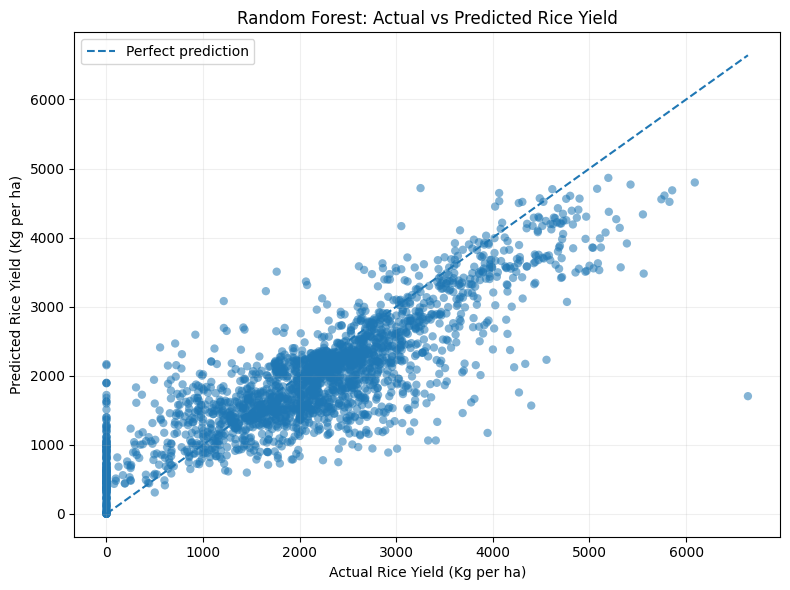

In [7]:
# BLOCK 7: Visualize actual versus predicted rice yield

plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, alpha=0.55, edgecolors="none")

# Reference line: perfect predictions lie on y = x.
axis_min = min(float(y_test.min()), float(np.min(predictions)))
axis_max = max(float(y_test.max()), float(np.max(predictions)))
plt.plot([axis_min, axis_max], [axis_min, axis_max], linestyle="--", linewidth=1.5, label="Perfect prediction")

plt.xlabel("Actual Rice Yield (Kg per ha)")
plt.ylabel("Predicted Rice Yield (Kg per ha)")
plt.title("Random Forest: Actual vs Predicted Rice Yield")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


,Feature,Importance
27,categories__State Name_Tamil Nadu,0.128435
4,numbers__TOTAL FERTILISER CONSUMPTION (tons),0.095365
25,categories__State Name_Punjab,0.094067
1,numbers__NITROGEN CONSUMPTION (tons),0.067647
23,categories__State Name_Maharashtra,0.053514
3,numbers__POTASH CONSUMPTION (tons),0.051462
7,numbers__Rainy JUN-SEP MAXIMUM TEMPERATURE (Ce...,0.048840
22,categories__State Name_Madhya Pradesh,0.043968
9,numbers__Rainy JUN-SEP PERCIPITATION (Millimet...,0.041375
6,numbers__GROSS IRRIGATED AREA (1000 ha),0.035230


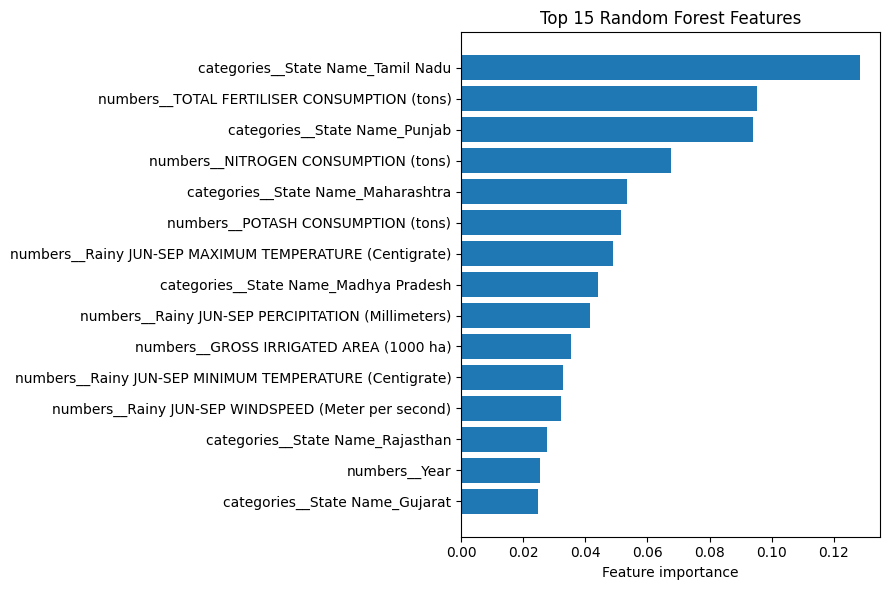

In [8]:
# BLOCK 8: Inspect Random Forest feature importance

# Feature names after one-hot encoding.
preprocessor_fitted = model.named_steps["preprocessor"]
feature_names = preprocessor_fitted.get_feature_names_out()
importances = model.named_steps["random_forest"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(feature_importance.head(15))

plt.figure(figsize=(9, 6))
top_features = feature_importance.head(15).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature importance")
plt.title("Top 15 Random Forest Features")
plt.tight_layout()
plt.show()


In [9]:
# BLOCK 9: Save predictions, metrics and trained model

predictions_path = os.path.join(OUTPUT_DIR, "random_forest_predictions.csv")
metrics_path = os.path.join(OUTPUT_DIR, "random_forest_metrics.json")
importance_path = os.path.join(OUTPUT_DIR, "random_forest_feature_importance.csv")
model_path = os.path.join(OUTPUT_DIR, "random_forest_rice_yield.joblib")

results.to_csv(predictions_path, index=False)
feature_importance.to_csv(importance_path, index=False)
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)
joblib.dump(model, model_path)

print("Saved output files:")
for path in [predictions_path, metrics_path, importance_path, model_path]:
    print("-", path)


Saved output files:
- /content/unit5_outputs/random_forest_predictions.csv
- /content/unit5_outputs/random_forest_metrics.json
- /content/unit5_outputs/random_forest_feature_importance.csv
- /content/unit5_outputs/random_forest_rice_yield.joblib
